Import Lib

1.   Pandas
2.   Matplotlib
3.   Seaborn
4.   Numpy




In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Export datasets
datasets:[Student_Mental_Health_Score](https://)

In [3]:
df =pd.read_csv('/content/sample_data/Student Social Media And Mental Health Impact.csv')
df

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7


In [4]:
#look at 4 rows
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [5]:
#look of total rows & columns
df.shape

(5000, 13)

In [6]:
#check null values
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [7]:
#check duplicated
df.duplicated().sum()

np.int64(2)

In [8]:
#info of datasets
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


# EDA

# target distribution

In [9]:
df.value_counts('Mental_Health_Score')

,count
Mental_Health_Score,
6.0,424
5.0,346
7.0,315
8.0,203
5.9,134
4.9,129
6.1,119
5.1,117
6.9,117


<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

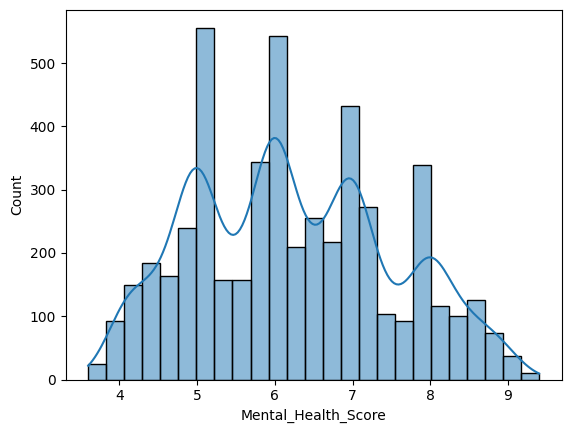

In [10]:
sns.histplot(df['Mental_Health_Score'],kde=True)  #kde

4.2 Correleation heatmap

<Axes: >

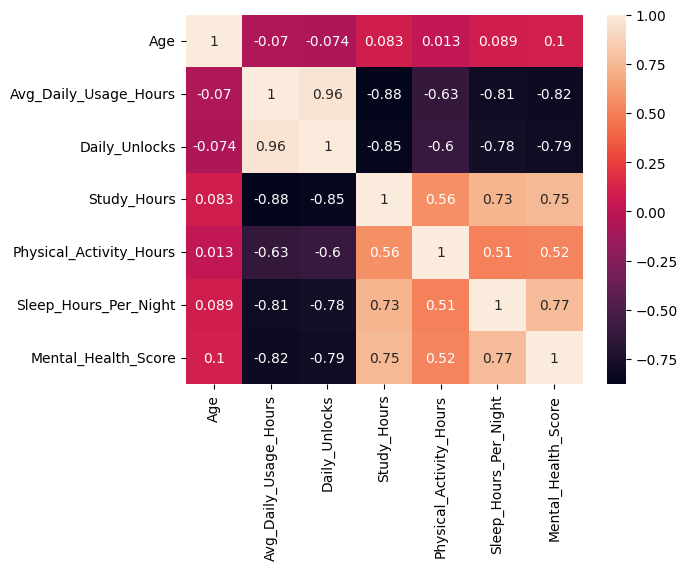

In [11]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

4.3 - Stress Level VS Mental Level

In [12]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

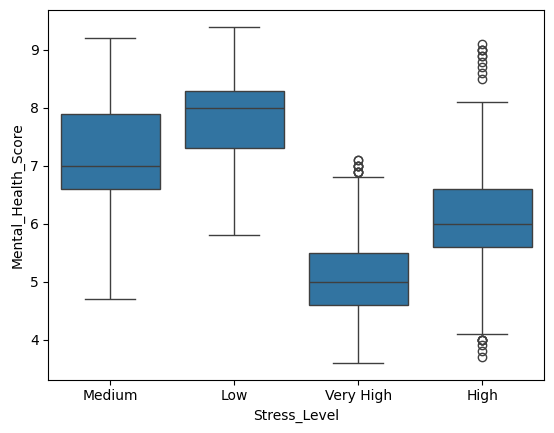

In [13]:
order=['Medium', 'Low', 'Very High', 'High']
sns.boxplot(x='Stress_Level',y='Mental_Health_Score',data=df,order=order)

Daily Usage Hours VS Mental Health Score

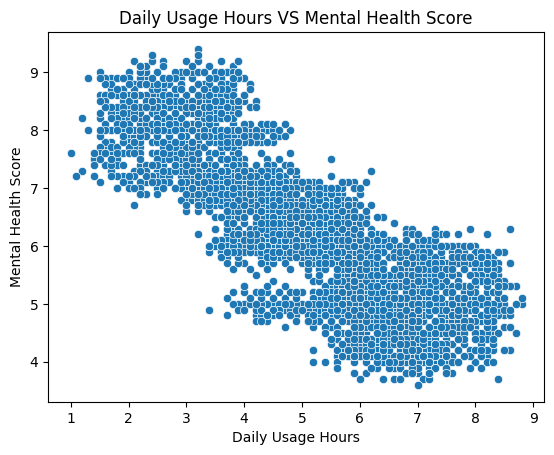

In [14]:
scatter,ax=plt.subplots()
ax=sns.scatterplot(x='Avg_Daily_Usage_Hours',y='Mental_Health_Score',data=df)
ax.set_title('Daily Usage Hours VS Mental Health Score')
ax.set_xlabel('Daily Usage Hours')
ax.set_ylabel('Mental Health Score')
plt.show()

  4.5- Sleep Hours VS Mental Health Score

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

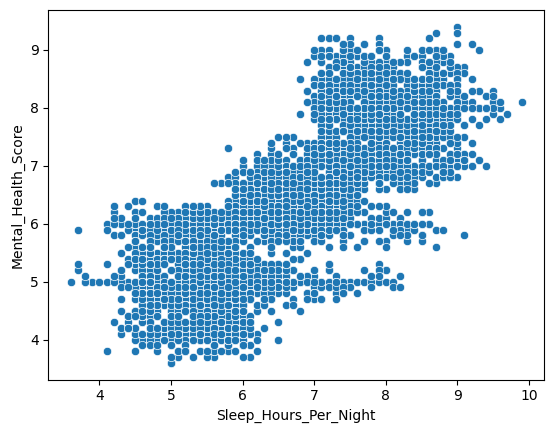

In [15]:
sns.scatterplot(x='Sleep_Hours_Per_Night',y='Mental_Health_Score',data=df)

Count Most Platforms

In [16]:
platform_counts=df['Most_Used_Platform'].value_counts()
platform_counts

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,523
YouTube,491
Twitter,462
Snapchat,420
WhatsApp,175
LINE,50


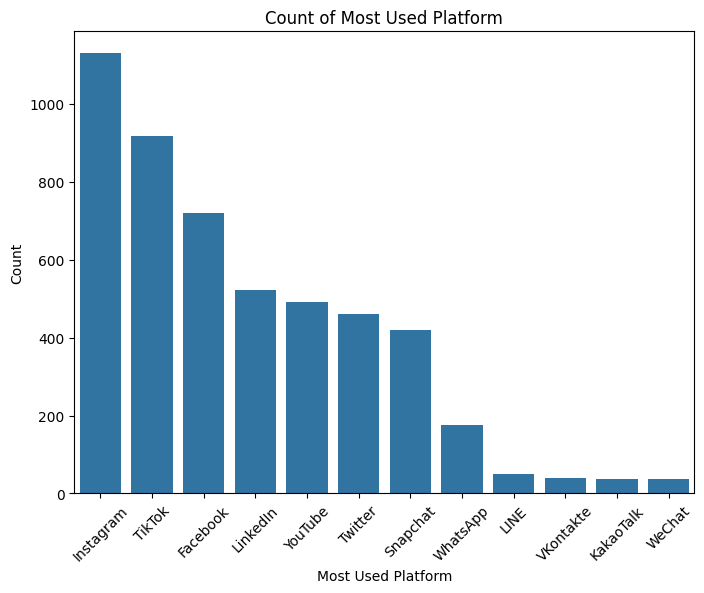

In [17]:
plt.figure(figsize=(8,6))
sns.countplot(x=df['Most_Used_Platform'],order=df['Most_Used_Platform'].value_counts().index)
plt.xticks(rotation=45,fontsize=10)
plt.xlabel('Most Used Platform')
plt.ylabel('Count')
plt.title('Count of Most Used Platform')
plt.show()

# Checking Outliers

In [18]:
num_features=df.select_dtypes(include='number')
Q1=num_features.quantile(0.25)
Q3=num_features.quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

Outilers=(num_features < lower_bound) | (num_features > upper_bound)
print(Outilers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


# 5.Data Cleaning

In [19]:
#describe  data
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [20]:
#drop duplicates and null data
drop=df.drop_duplicates()

#compare negative -0.400000 in 	Physical_Activity_Hours in convert zero
df['Physical_Activity_Hours']=df['Physical_Activity_Hours'].clip(lower=0)

# 6. Skewness

In [21]:
num_cols=df.select_dtypes(include='number')
num_cols.skew()

#near to 0 in the skew value then they are centeralized skew (0.1 to 0.0002)
#negative value then Left skewed
#positive value then right skewed

,0
Age,0.155325
Avg_Daily_Usage_Hours,0.005606
Daily_Unlocks,0.002351
Study_Hours,0.435819
Physical_Activity_Hours,0.052632
Sleep_Hours_Per_Night,0.124050
Mental_Health_Score,0.206567


#7. Feature Engineering

In [22]:
top_countries=df['Country'].value_counts().index[:10].tolist()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [23]:
def group_countries(Country):
  if Country in top_countries:
    return Country
  else:
    return 'other'

In [24]:
df['Group_country']=df['Country'].apply(group_countries)
df['Group_country'].value_counts()

,count
Group_country,
Other,1880
other,1352
India,389
USA,355
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94


# 8.Encoding Strategy

# 9.Train - Test Split



In [25]:
from sklearn.model_selection import train_test_split

skwewd_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Country"]


feature_col = skwewd_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# 10.Pre Processing & Column Transformation

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
#1. Skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())

])

#2. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

#3. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

#4. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])


    # (konsi_pipeline, konsa_feature)
preprocessor = ColumnTransformer(transformers=[
    ("Skewed_Pipeline", skew_pipeline, skwewd_col),
    ("Plain_Numeric",plain_numeric_pipeline, other_numeric_cols ),
    ('Ordinal', ordinal_pipeline, ordinal_col),
    ('Normal', nominal_pipeline, normal_col)
])


# 11.Build a Pipline

# 12.Model Building



# 12.1- Baseline:Linear Regression



In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,median_absolute_error,mean_squared_error,mean_absolute_error
lr_pipline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor',LinearRegression())
])

lr_pipline.fit(X_train,y_train)
lr_preds=lr_pipline.predict(X_test)
lr_preds_train=lr_pipline.predict(X_train)


lr_r2_testing=r2_score(y_test,lr_preds)
lr_r2_training=r2_score(y_train,lr_preds_train)
lr_mae_testing=mean_absolute_error(y_test,lr_preds)

print(f"Accuracy of testing: {lr_r2_testing}")
print(f"Accuracy of training: {lr_r2_training}")
print(f"Mae",lr_mae_testing)


Accuracy of testing: 0.7907430005268095
Accuracy of training: 0.7781304948700498
Mae 0.47139769649731594


# 12.2  Random Forest

In [28]:
from sklearn.ensemble import RandomForestRegressor

rf_pipline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('random forest',RandomForestRegressor(random_state=42))
])

rf_pipline.fit(X_train,y_train)
rf_preds=rf_pipline.predict(X_test)
rf_preds_train=rf_pipline.predict(X_train)


rf_r2_testing=r2_score(y_test,rf_preds)
rf_r2_training=r2_score(y_train,rf_preds_train)
rf_mae_testing=mean_absolute_error(y_test,rf_preds)

print(f"Accuracy of testing: {rf_r2_testing}")
print(f"Accuracy of training: {rf_r2_training}")
print(f"Mae",rf_mae_testing)

Accuracy of testing: 0.911489387575932
Accuracy of training: 0.9864977178837605
Mae 0.28720957777777795


# 12.3 Hypermeter Tunning the Random Forest

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'       : [100,200,300],
    'random forest__max_depth'         : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf'  : [1,2,4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipline,
    param_distributions=param_grid,
    n_iter = 15,
    cv = 5,
    scoring='r2',
    random_state=42,
    n_jobs =-1 #processor free
)

random_search.fit(X_train, y_train)

In [ ]:
random_search.best_params_

In [ ]:

rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")

# 13.Model Evaluation


In [ ]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae_testing, rf_mae_testing, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)


# 14.Save Model


In [ ]:
import joblib

# Saving the best tuned pipeline
joblib.dump(rf_best_pipeline, 'Mental_Health_Model.pkl')